# Task 02: Titanic Data Cleaning and EDA

<a href="https://colab.research.google.com/github/alhaddad-a/PRODIGY_DS/blob/main/Task_02_Titanic_EDA/Task2_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prodigy InfoTech Data Science Internship

Task: perform data cleaning and exploratory data analysis (EDA) on a dataset of your choice, explore the relationships between variables and identify patterns and trends.

Data: Kaggle Titanic training set (891 passengers, survival known). Source: https://www.kaggle.com/c/titanic/data

## 1. Problem statement

On 15 April 1912 the Titanic sank and 1,502 of the 2,224 people on board died. Survival was not random: there were not enough lifeboats, and who got into them depended on rules ("women and children first"), on where people were on the ship, and on social class.

**Business question:** which passenger characteristics were associated with surviving, and how strongly?

This is framed as the first step of a classification problem (target = `Survived`). Before any model, I need to:

1. Find and fix data quality problems (missing values, wrong types, outliers).
2. Check each variable on its own.
3. Measure how each variable relates to survival, and look for confounders.
4. Create features that a model could use later.

**Hypotheses to test**

| # | Hypothesis |
|---|---|
| H1 | Women survived more than men. |
| H2 | Higher classes survived more than lower classes. |
| H3 | Children survived more than adults. |
| H4 | Port of embarkation mattered. |
| H5 | Travelling alone vs. with family changed the chance of survival. |

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

os.makedirs("images", exist_ok=True)

SURV = "#2a78d6"   # survived
DIED = "#eb6834"   # died
GREY = "#9aa0a6"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def save(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

def pct_axis(ax):
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.set_ylim(0, 1)

def label_bars(ax, fmt="{:.0%}"):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], padding=2, fontsize=9)

## 2. Load data

In [2]:
url = "https://raw.githubusercontent.com/Prodigy-InfoTech/data-science-datasets/main/Task%202/train.csv"
raw = pd.read_csv(url)
print(raw.shape)
raw.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


| Column | Meaning |
|---|---|
| Survived | 0 = died, 1 = survived (target) |
| Pclass | Ticket class: 1 = upper, 2 = middle, 3 = lower |
| SibSp / Parch | Number of siblings+spouses / parents+children aboard |
| Fare | Ticket price in pounds (one ticket can cover several people) |
| Cabin | Cabin number, e.g. C85 (first letter = deck) |
| Embarked | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

## 3. Data quality check

In [4]:
missing = raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
summary = pd.DataFrame({"missing": missing, "percent": (missing / len(raw)).round(3)})
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate PassengerId:", raw["PassengerId"].duplicated().sum())
summary

Duplicate rows: 0
Duplicate PassengerId: 0


,missing,percent
Cabin,687,0.771
Age,177,0.199
Embarked,2,0.002


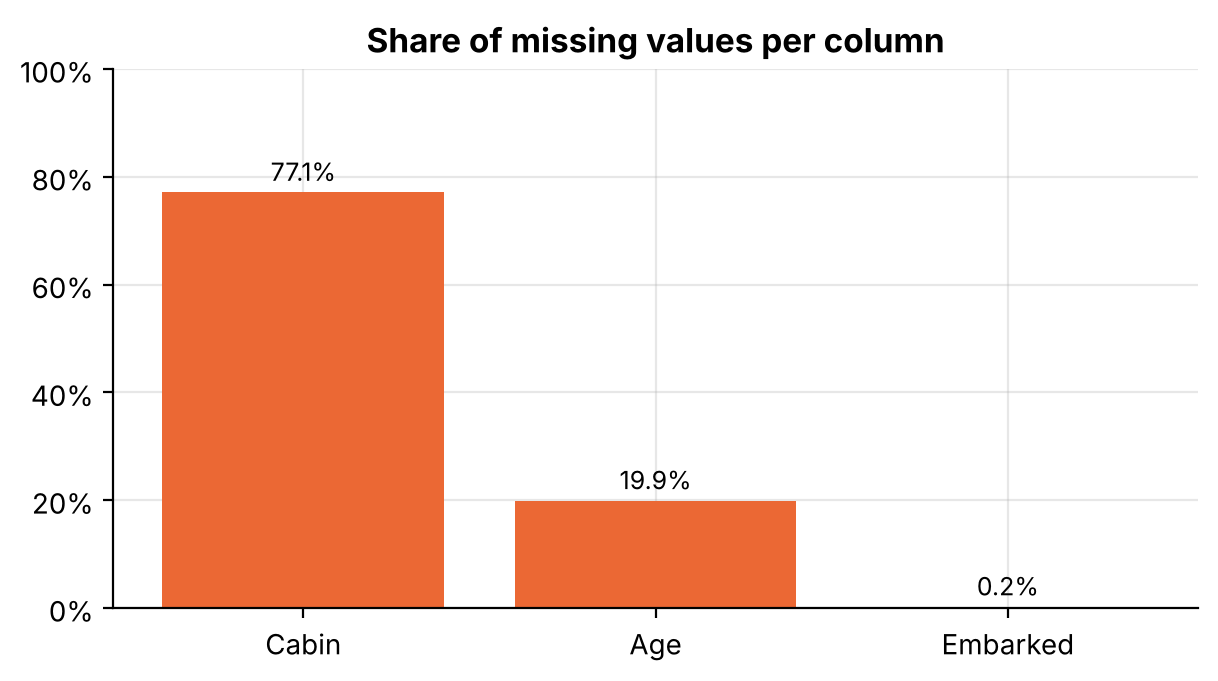

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(summary.index, summary["percent"], color=DIED)
pct_axis(ax)
label_bars(ax, "{:.1%}")
ax.set_title("Share of missing values per column")
save(fig, "01_missing_values")
plt.show()

Three columns have gaps:

- **Cabin (77% missing):** too sparse to impute. The fact that it is missing is still informative (cabins were mostly recorded for 1st class), so I keep a `HasCabin` flag and the deck letter, and mark the rest as `U` (unknown).
- **Age (20% missing):** too many rows to drop. Imputing one global median would ignore that a "Master" is a boy and a "Mrs" is an adult. I impute the median age by **title and class** instead.
- **Embarked (2 rows):** both are first-class women on the same ticket (113572, cabin B28).

In [6]:
raw[raw["Embarked"].isna()][["PassengerId", "Name", "Pclass", "Fare", "Cabin", "Ticket"]]

,PassengerId,Name,Pclass,Fare,Cabin,Ticket
61,62,"Icard, Miss. Amelie",1,80.0,B28,113572
829,830,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.0,B28,113572


In [7]:
# What do 1st-class tickets usually cost from each port?
raw[raw["Pclass"] == 1].groupby("Embarked")["Fare"].median()

Embarked
C    78.2667
Q    90.0000
S    52.0000
Name: Fare, dtype: float64

A fare of 80 sits between the Cherbourg and Southampton medians, so the data alone doesn't settle it. Passenger records (Encyclopedia Titanica) show Mrs Stone and her maid Miss Icard boarded at **Southampton**, so I fill `S`, which is also the most common port.

### Outliers

Fare is very skewed. I check the extremes and the zero fares before deciding anything.

In [8]:
print(raw["Fare"].describe().round(2))
print("\nZero fares:", (raw["Fare"] == 0).sum())
raw.nlargest(4, "Fare")[["Name", "Pclass", "Fare", "Ticket"]]

count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: Fare, dtype: float64

Zero fares: 15


,Name,Pclass,Fare,Ticket
258,"Ward, Miss. Anna",1,512.3292,PC 17755
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755
27,"Fortune, Mr. Charles Alexander",1,263.0000,19950


- The 512 fares are real (a shared first-class ticket, PC 17755), so I keep them. They are high because one ticket price covers several people.
- To compare fares fairly, I compute **fare per person** = Fare / number of passengers on the same ticket.
- The 15 zero fares look like free tickets (historical records indicate several were shipbuilder or shipping-line staff). They are valid passengers, so I keep them.

## 4. Cleaning and feature engineering

In [9]:
df = raw.copy()

# Title from name, e.g. "Braund, Mr. Owen Harris" -> "Mr"
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
title_map = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "the Countess": "Rare", "Sir": "Rare", "Don": "Rare", "Jonkheer": "Rare",
    "Dr": "Rare", "Rev": "Rare", "Major": "Rare", "Col": "Rare", "Capt": "Rare",
}
df["Title"] = df["Title"].replace(title_map)
print(df["Title"].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [10]:
# Age: median by Title and Pclass, computed only from known ages
df["AgeMissing"] = df["Age"].isna().astype(int)
age_median = df.groupby(["Title", "Pclass"])["Age"].transform("median")
df["Age"] = df["Age"].fillna(age_median)
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))

# Embarked: historical record (see above)
df["Embarked"] = df["Embarked"].fillna("S")

# Cabin -> deck + flag
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("U")

# Family and ticket features
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["FamilyGroup"] = pd.cut(df["FamilySize"], [0, 1, 4, 11], labels=["Alone (1)", "Small (2-4)", "Large (5+)"])
df["TicketCount"] = df.groupby("Ticket")["Ticket"].transform("count")
df["FarePerPerson"] = df["Fare"] / df["TicketCount"]

# Age groups
df["AgeGroup"] = pd.cut(df["Age"], [0, 12, 18, 30, 50, 80],
                        labels=["Child (0-12)", "Teen (13-18)", "Young adult (19-30)", "Adult (31-50)", "Senior (51+)"])

# Types
df["Sex"] = df["Sex"].astype("category")
df["Embarked"] = df["Embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
df["ClassName"] = df["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"})

print("Missing values left:")
print(df.drop(columns="Cabin").isna().sum().sum())
df.head()

Missing values left:
0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,AgeMissing,HasCabin,Deck,FamilySize,IsAlone,FamilyGroup,TicketCount,FarePerPerson,AgeGroup,ClassName
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,0,0,U,2,0,Small (2-4),1,7.2500,Young adult (19-30),3rd
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,0,1,C,2,0,Small (2-4),1,71.2833,Adult (31-50),1st
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,0,0,U,1,1,Alone (1),1,7.9250,Young adult (19-30),3rd
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,0,1,C,2,0,Small (2-4),2,26.5500,Adult (31-50),1st
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,0,0,U,1,1,Alone (1),1,8.0500,Adult (31-50),3rd


Sanity check: imputing should not distort the age distribution much. Imputed ages cluster around the group medians (expected), and the overall median moves only from 28 to 26.

In [11]:
print(f"Median age before: {raw['Age'].median():.1f}")
print(f"Median age after:  {df['Age'].median():.1f}")
print(df.groupby("Title")["Age"].median().round(1))

Median age before: 28.0
Median age after:  26.0
Title
Master     4.0
Miss      18.0
Mr        28.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64


## 5. Univariate analysis

Overall survival rate: 38.4%  (342 of 891)


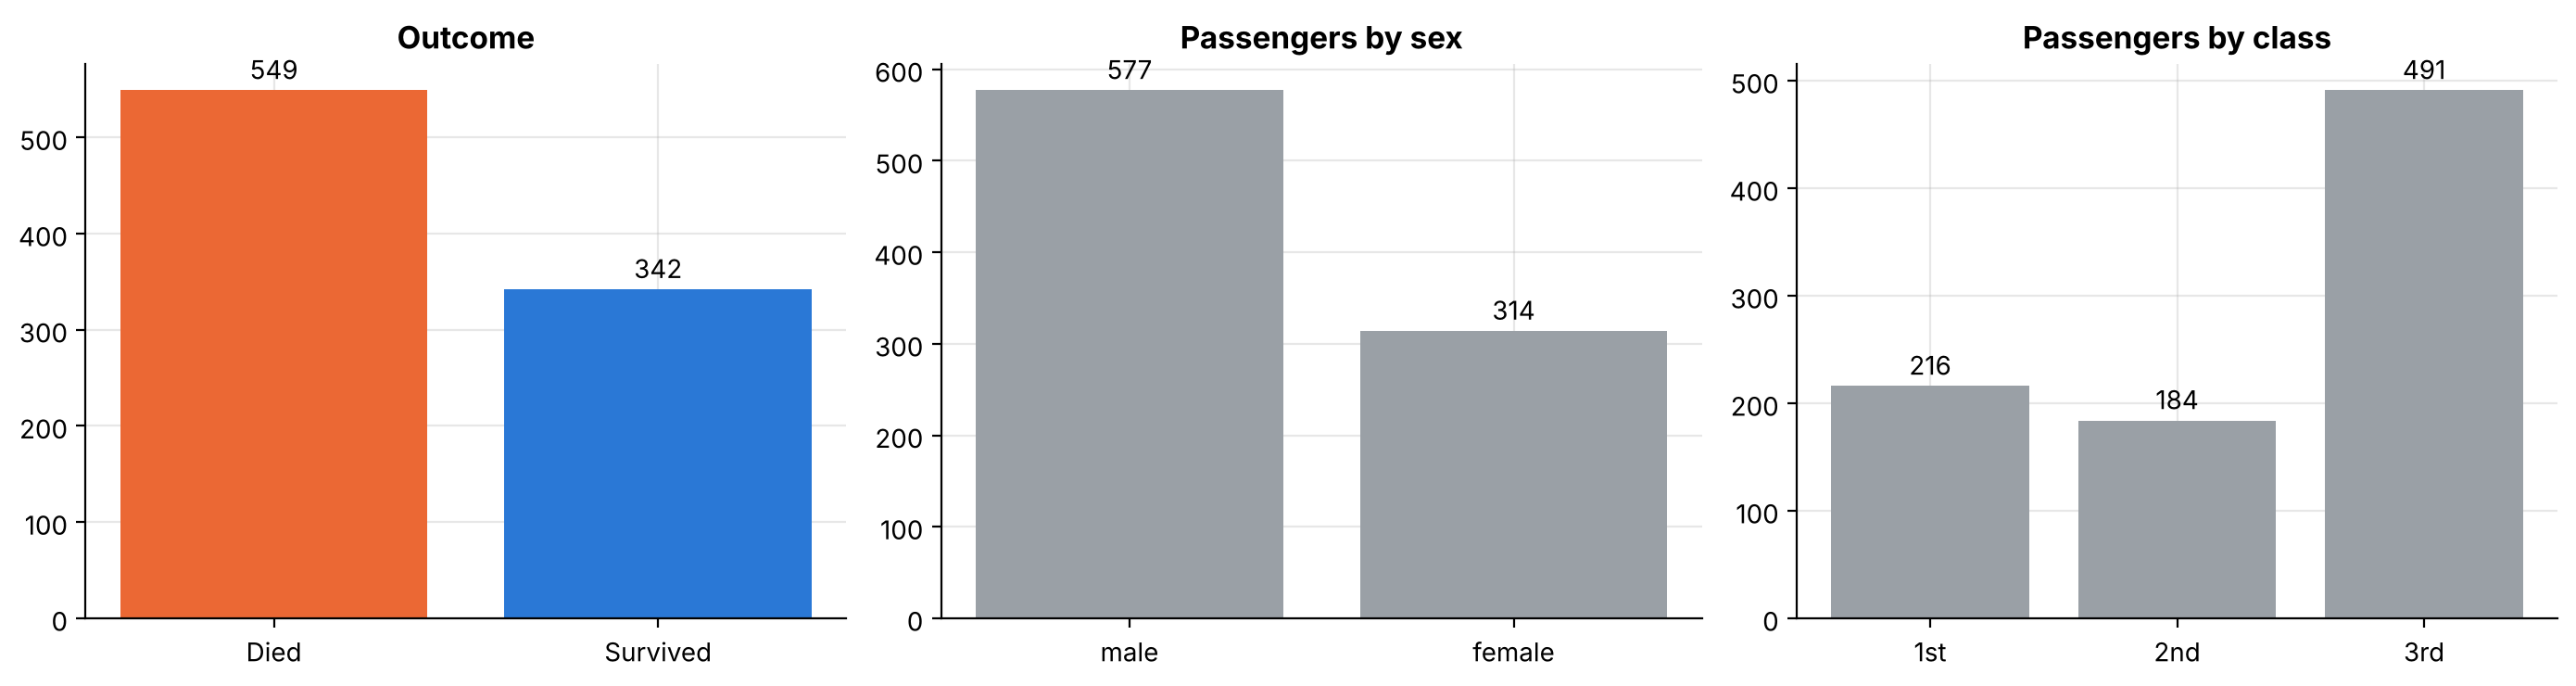

In [12]:
print(f"Overall survival rate: {df['Survived'].mean():.1%}  ({df['Survived'].sum()} of {len(df)})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
counts = df["Survived"].map({0: "Died", 1: "Survived"}).value_counts()
axes[0].bar(counts.index, counts.values, color=[DIED, SURV])
axes[0].set_title("Outcome")
for c in axes[0].containers:
    axes[0].bar_label(c, padding=2)

sex = df["Sex"].value_counts()
axes[1].bar(sex.index, sex.values, color=GREY)
axes[1].set_title("Passengers by sex")
for c in axes[1].containers:
    axes[1].bar_label(c, padding=2)

cls = df["ClassName"].value_counts().sort_index()
axes[2].bar(cls.index, cls.values, color=GREY)
axes[2].set_title("Passengers by class")
for c in axes[2].containers:
    axes[2].bar_label(c, padding=2)
fig.tight_layout()
save(fig, "02_univariate_counts")
plt.show()

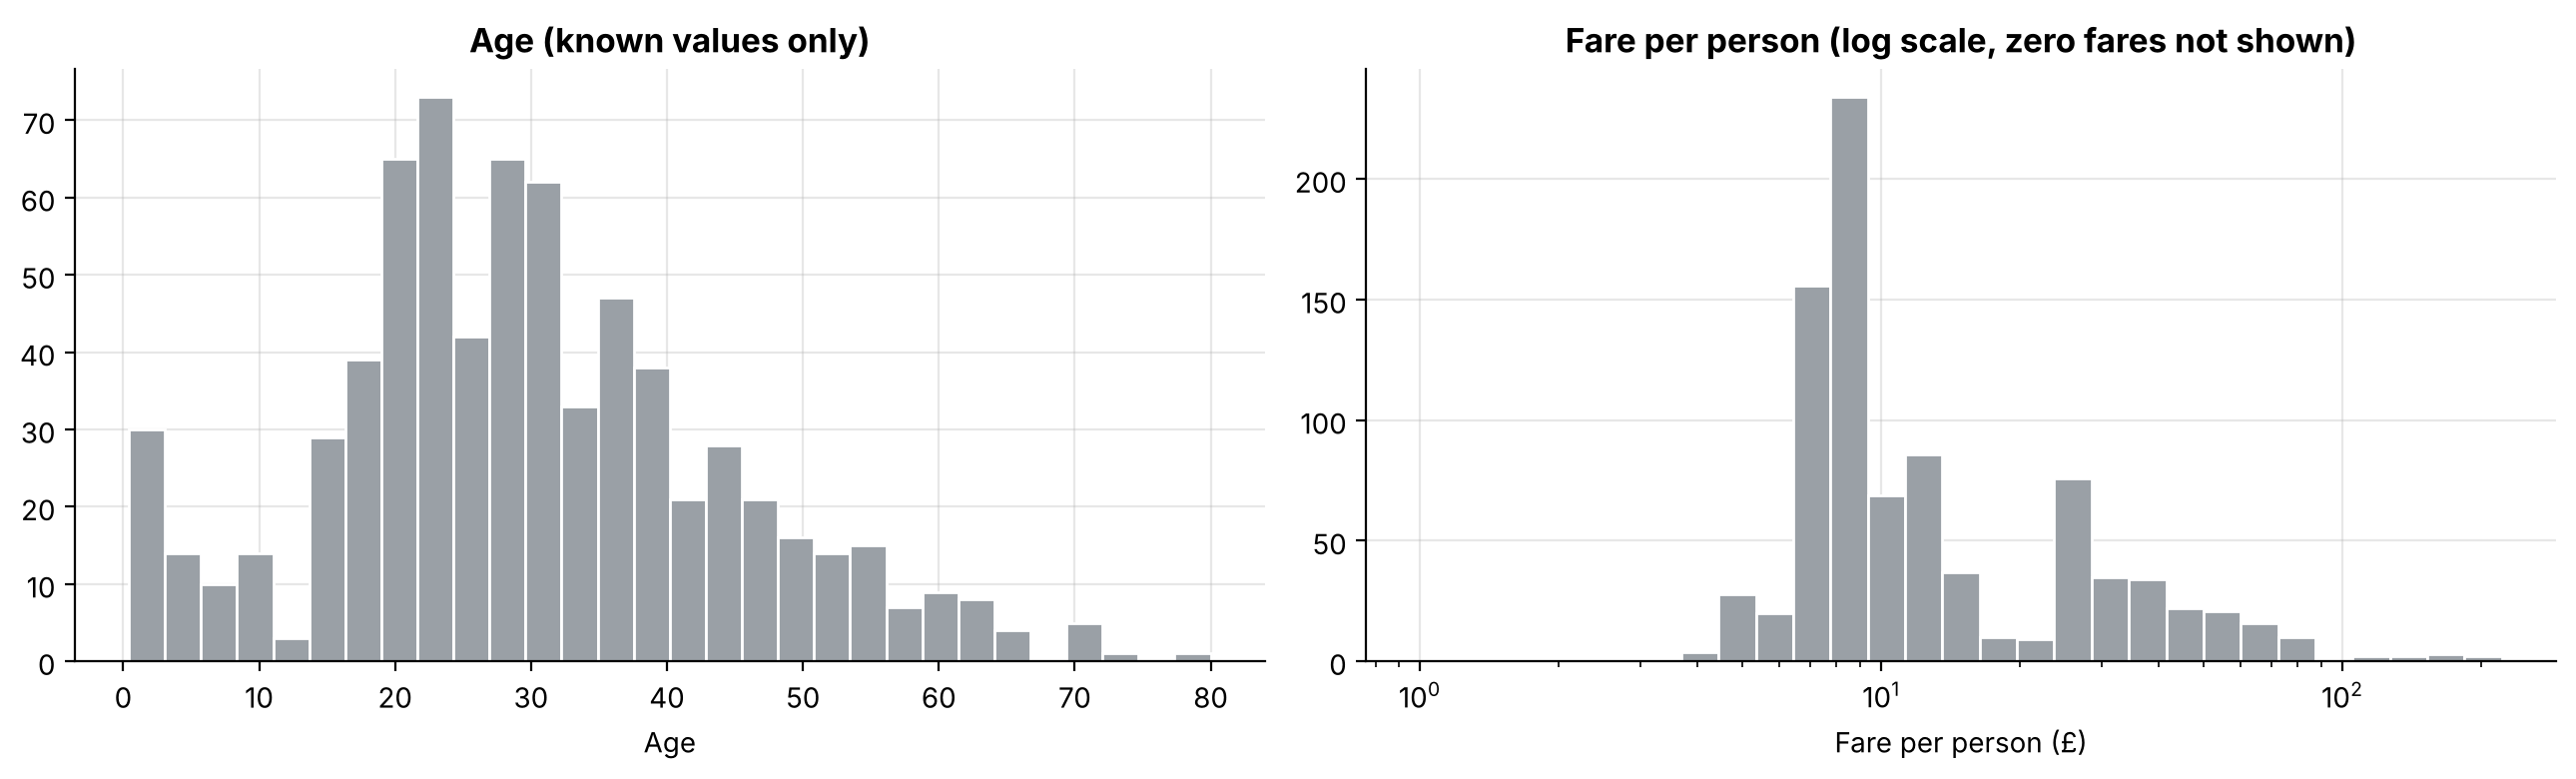

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df.loc[df["AgeMissing"] == 0, "Age"], bins=30, color=GREY, edgecolor="white")
axes[0].set_title("Age (known values only)")
axes[0].set_xlabel("Age")

axes[1].hist(df["FarePerPerson"], bins=np.logspace(0, np.log10(df["FarePerPerson"].max()), 30),
             color=GREY, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Fare per person (log scale, zero fares not shown)")
axes[1].set_xlabel("Fare per person (£)")
fig.tight_layout()
save(fig, "03_age_fare_distribution")
plt.show()

- 62% died, so the classes are imbalanced but not extremely.
- Passengers were mostly male (65%) and mostly 3rd class (55%).
- Age is centred on the 20s-30s with a small bump of young children.
- Fare per person is right-skewed even on a log scale, with clusters that match the three classes.

## 6. Bivariate analysis: what is related to survival?

### H1 and H2: sex and class

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Sex        female   male
ClassName               
1st         0.968  0.369
2nd         0.921  0.157
3rd         0.500  0.135


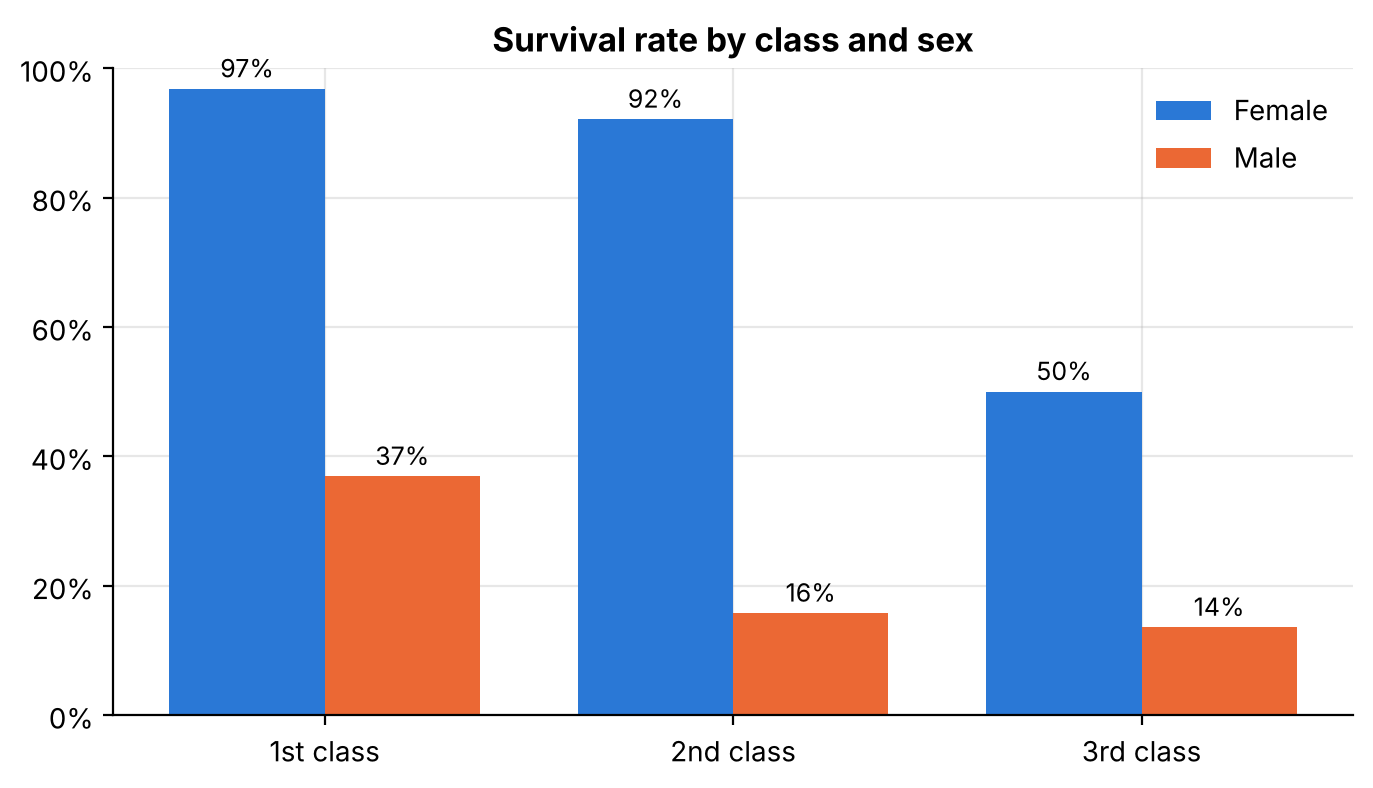

In [14]:
pivot = df.pivot_table(values="Survived", index="ClassName", columns="Sex", aggfunc="mean", observed=True)
print(df.groupby("Sex", observed=True)["Survived"].mean().round(3))
print(pivot.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(pivot))
w = 0.38
ax.bar(x - w/2, pivot["female"], w, label="Female", color=SURV)
ax.bar(x + w/2, pivot["male"], w, label="Male", color=DIED)
ax.set_xticks(x, [f"{c} class" for c in pivot.index])
pct_axis(ax)
label_bars(ax)
ax.legend(frameon=False)
ax.set_title("Survival rate by class and sex")
save(fig, "04_survival_class_sex")
plt.show()

Both hypotheses hold, and the effect of sex is much larger than the effect of class:

- 74% of women survived vs 19% of men.
- In 1st and 2nd class over 90% of women survived. In 3rd class it was only 50%.
- A 1st-class man (37%) had a lower chance than a 3rd-class woman (50%).

### H3: age

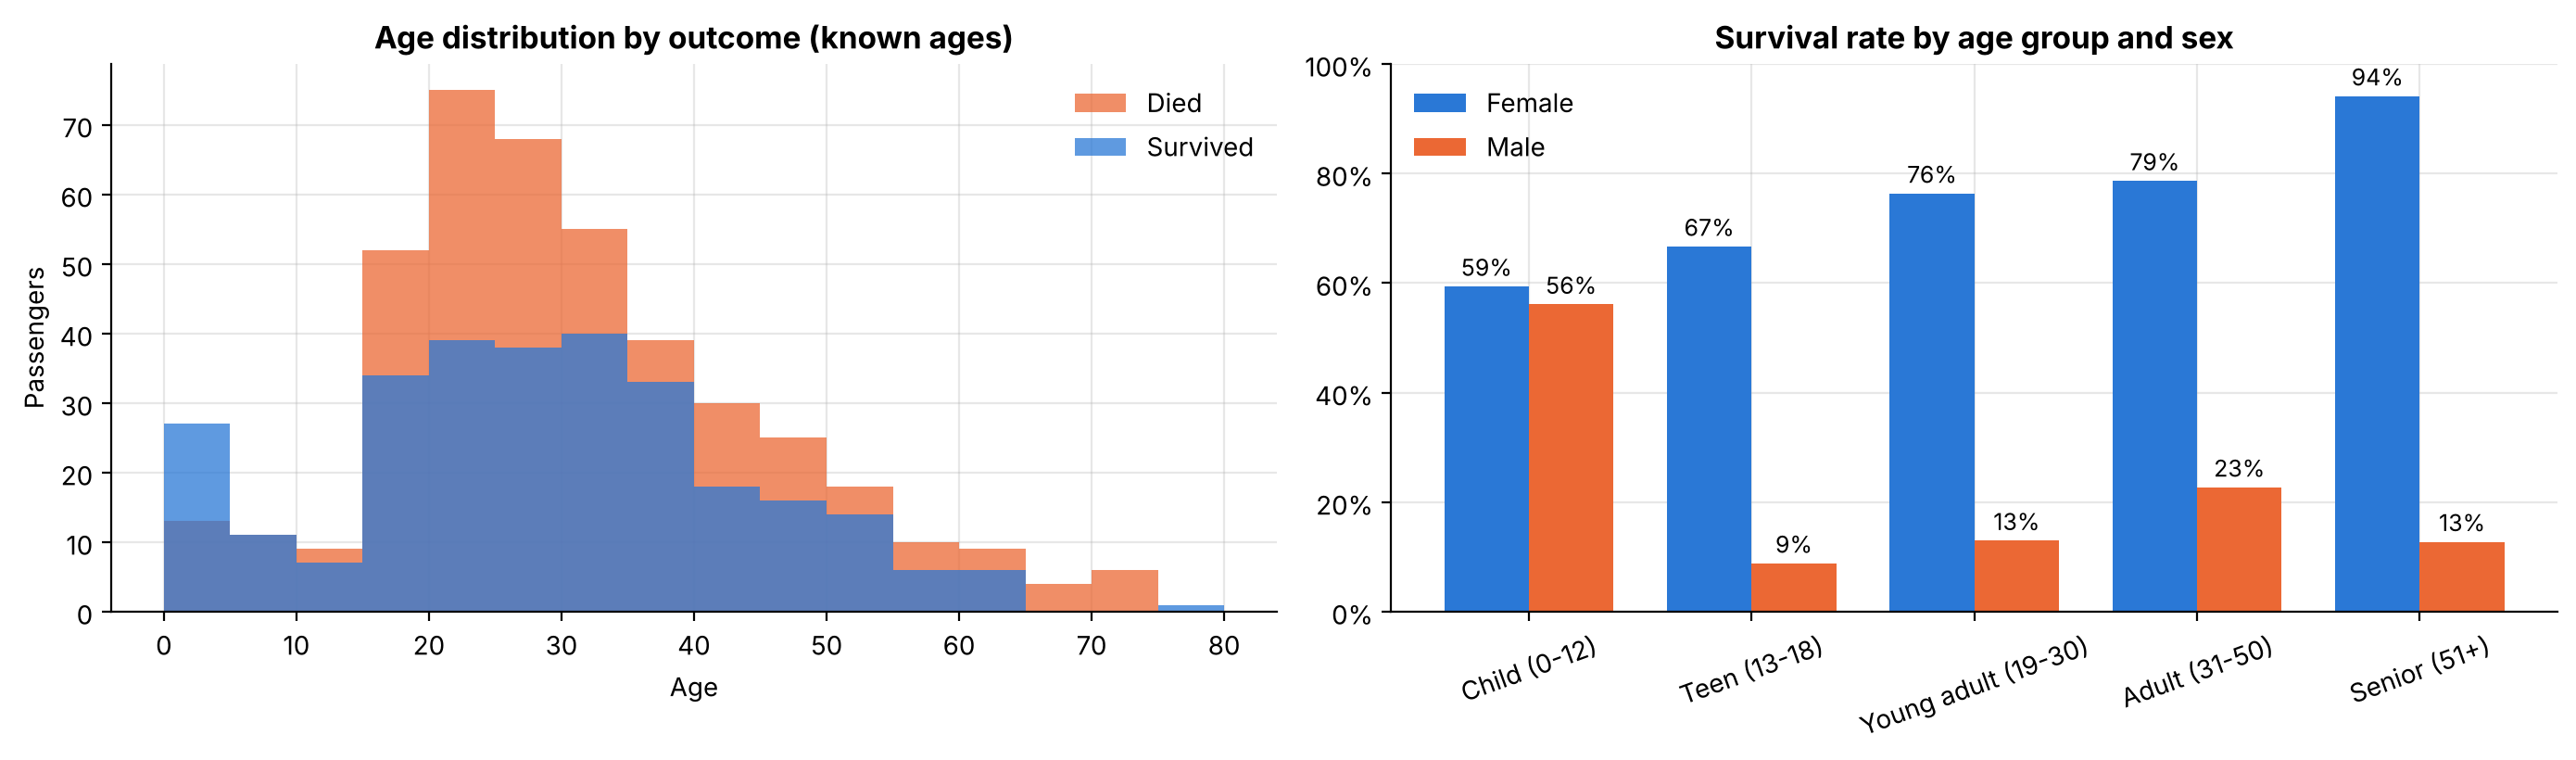

,mean,size
AgeGroup,,
Child (0-12),0.575,73
Teen (13-18),0.476,103
Young adult (19-30),0.292,363
Adult (31-50),0.427,288
Senior (51+),0.344,64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

bins = np.arange(0, 85, 5)
known = df[df["AgeMissing"] == 0]
axes[0].hist(known.loc[known["Survived"] == 0, "Age"], bins=bins, color=DIED, alpha=0.75, label="Died")
axes[0].hist(known.loc[known["Survived"] == 1, "Age"], bins=bins, color=SURV, alpha=0.75, label="Survived")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Passengers")
axes[0].legend(frameon=False)
axes[0].set_title("Age distribution by outcome (known ages)")

ag = df.pivot_table(values="Survived", index="AgeGroup", columns="Sex", aggfunc="mean", observed=True)
x = np.arange(len(ag))
axes[1].bar(x - w/2, ag["female"], w, label="Female", color=SURV)
axes[1].bar(x + w/2, ag["male"], w, label="Male", color=DIED)
axes[1].set_xticks(x, ag.index, rotation=20)
pct_axis(axes[1])
label_bars(axes[1])
axes[1].legend(frameon=False)
axes[1].set_title("Survival rate by age group and sex")
fig.tight_layout()
save(fig, "05_survival_age")
plt.show()

df.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "size"]).round(3)

H3 holds mainly for young children. Children under 13 survived at 58%, and boys under 13 survived at 56% compared with 16% for adult men. After childhood, sex matters far more than age: the lowest group, young adults (29%), is low mainly because it is dominated by 3rd-class men.

### H4: port of embarkation, and a confounder

Embarked
Cherbourg      0.554
Queenstown     0.390
Southampton    0.339
Name: Survived, dtype: float64
ClassName     1st   2nd   3rd
Embarked                     
Cherbourg    0.51  0.10  0.39
Queenstown   0.03  0.04  0.94
Southampton  0.20  0.25  0.55


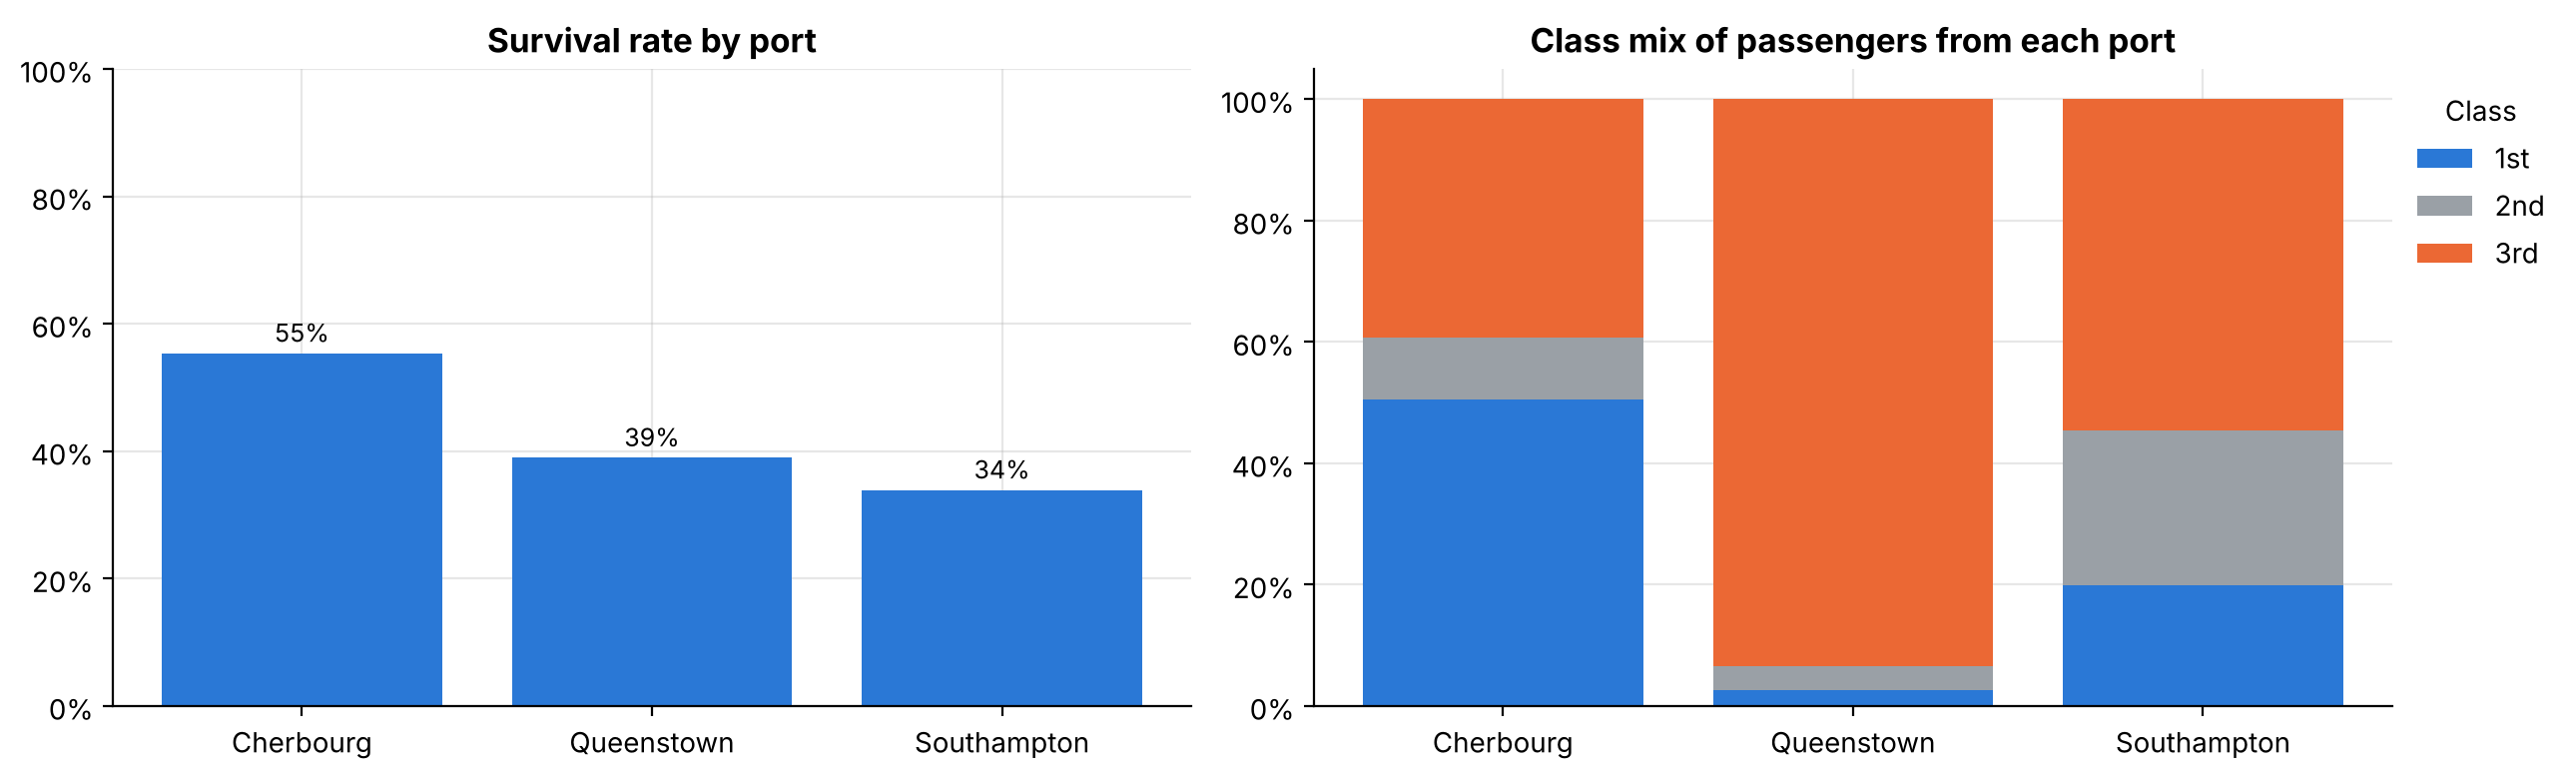

In [16]:
emb = df.groupby("Embarked")["Survived"].mean().sort_values(ascending=False)
mix = pd.crosstab(df["Embarked"], df["ClassName"], normalize="index").loc[emb.index]
print(emb.round(3))
print(mix.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(emb.index, emb.values, color=SURV)
pct_axis(axes[0])
label_bars(axes[0])
axes[0].set_title("Survival rate by port")

bottom = np.zeros(len(mix))
for col, color in zip(["1st", "2nd", "3rd"], [SURV, GREY, DIED]):
    axes[1].bar(mix.index, mix[col], bottom=bottom, label=col, color=color)
    bottom += mix[col].values
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].legend(title="Class", frameon=False, bbox_to_anchor=(1, 1))
axes[1].set_title("Class mix of passengers from each port")
fig.tight_layout()
save(fig, "06_embarked_confounder")
plt.show()

In [17]:
# Does the port still matter once class and sex are fixed?
df.pivot_table(values="Survived", index=["Sex", "ClassName"], columns="Embarked", aggfunc="mean", observed=True).round(2)

Embarked          Cherbourg  Queenstown  Southampton
Sex    ClassName                                    
female 1st             0.98        1.00         0.96
       2nd             1.00        1.00         0.91
       3rd             0.65        0.73         0.38
male   1st             0.40        0.00         0.35
       2nd             0.20        0.00         0.15
       3rd             0.23        0.08         0.13

Cherbourg passengers survived most (55%), but the port itself is probably not the cause. Half of Cherbourg passengers were in 1st class, compared with a fifth from Southampton and 3% from Queenstown. Within the same sex and class, most of the gap disappears for 1st and 2nd class. One difference remains: 3rd-class women from Southampton survived at 38% vs 65-73% from the other ports (but only 23 and 33 women in those groups). So H4 is **mostly a class effect (a confounder)**, with a smaller leftover effect for 3rd-class women. A model should not read too much into `Embarked`.

### H5: family size

             mean  size
FamilySize             
1           0.304   537
2           0.553   161
3           0.578   102
4           0.724    29
5           0.200    15
6           0.136    22
7           0.333    12
8           0.000     6
11          0.000     7


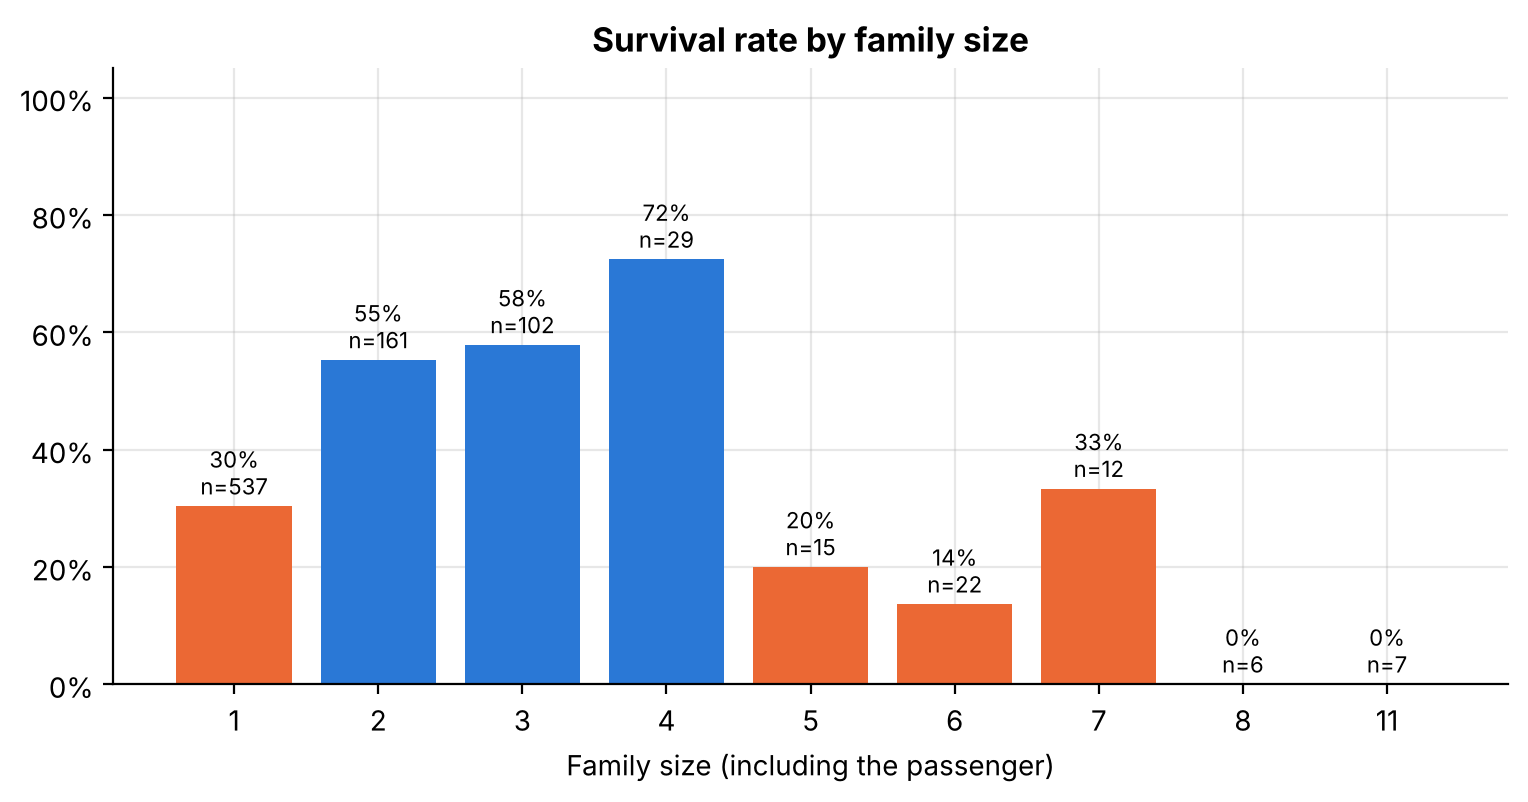

In [18]:
fam = df.groupby("FamilySize")["Survived"].agg(["mean", "size"])
print(fam.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [SURV if 2 <= s <= 4 else DIED for s in fam.index]
ax.bar(fam.index.astype(str), fam["mean"], color=colors)
for i, (m, n) in enumerate(zip(fam["mean"], fam["size"])):
    ax.text(i, m + 0.02, f"{m:.0%}\nn={n}", ha="center", fontsize=8)
pct_axis(ax)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Family size (including the passenger)")
ax.set_title("Survival rate by family size")
save(fig, "07_survival_family_size")
plt.show()

The relationship is not linear, it is an inverted U:

- Alone: 30%.
- Small families of 2-4: 55-72%.
- Large families of 5 or more: mostly 20% or lower, and none of the 13 people in families of 8 or 11 survived. 54 of the 62 people in families of 5+ were in 3rd class.

This is a good example of why feature engineering matters. `SibSp` and `Parch` each have a weak linear correlation with survival, but the grouped `FamilySize` shows a strong pattern.

### Title, fare and deck

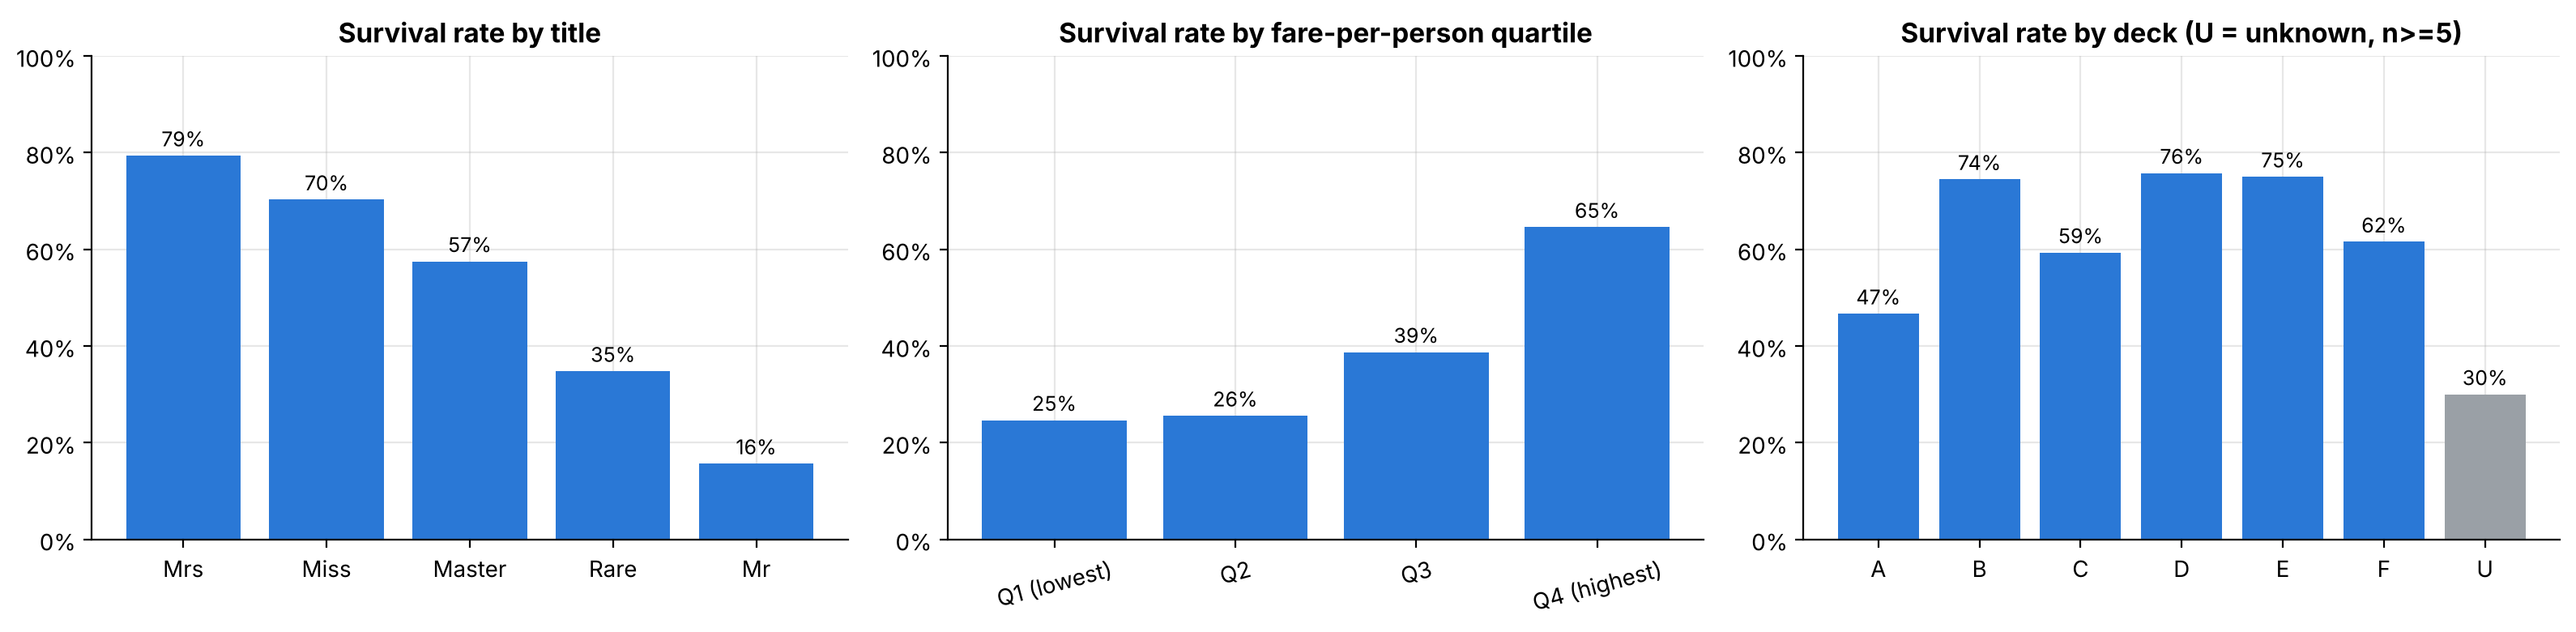

,mean,size
Title,,
Mrs,0.794,126
Miss,0.703,185
Master,0.575,40
Rare,0.348,23
Mr,0.157,517


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

t = df.groupby("Title")["Survived"].agg(["mean", "size"]).sort_values("mean", ascending=False)
axes[0].bar(t.index, t["mean"], color=SURV)
pct_axis(axes[0])
label_bars(axes[0])
axes[0].set_title("Survival rate by title")

df["FareBand"] = pd.qcut(df["FarePerPerson"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
f = df.groupby("FareBand", observed=True)["Survived"].mean()
axes[1].bar(f.index, f.values, color=SURV)
pct_axis(axes[1])
label_bars(axes[1])
axes[1].set_title("Survival rate by fare-per-person quartile")
axes[1].tick_params(axis="x", rotation=15)

d = df.groupby("Deck")["Survived"].agg(["mean", "size"]).sort_index()
d = d[d["size"] >= 5]
axes[2].bar(d.index, d["mean"], color=[GREY if i == "U" else SURV for i in d.index])
pct_axis(axes[2])
label_bars(axes[2])
axes[2].set_title("Survival rate by deck (U = unknown, n>=5)")
fig.tight_layout()
save(fig, "08_title_fare_deck")
plt.show()
t.round(3)

- **Title** combines sex and age in one variable: "Master" (boys) survived at 57% while "Mr" survived at 16%.
- **Fare** rises with survival, but it mostly measures class.
- **Deck:** passengers with a known deck survived at 67%, unknown at 30%. Known cabins were mostly 1st class, so this is again partly a class effect.

## 7. Multivariate view: correlations

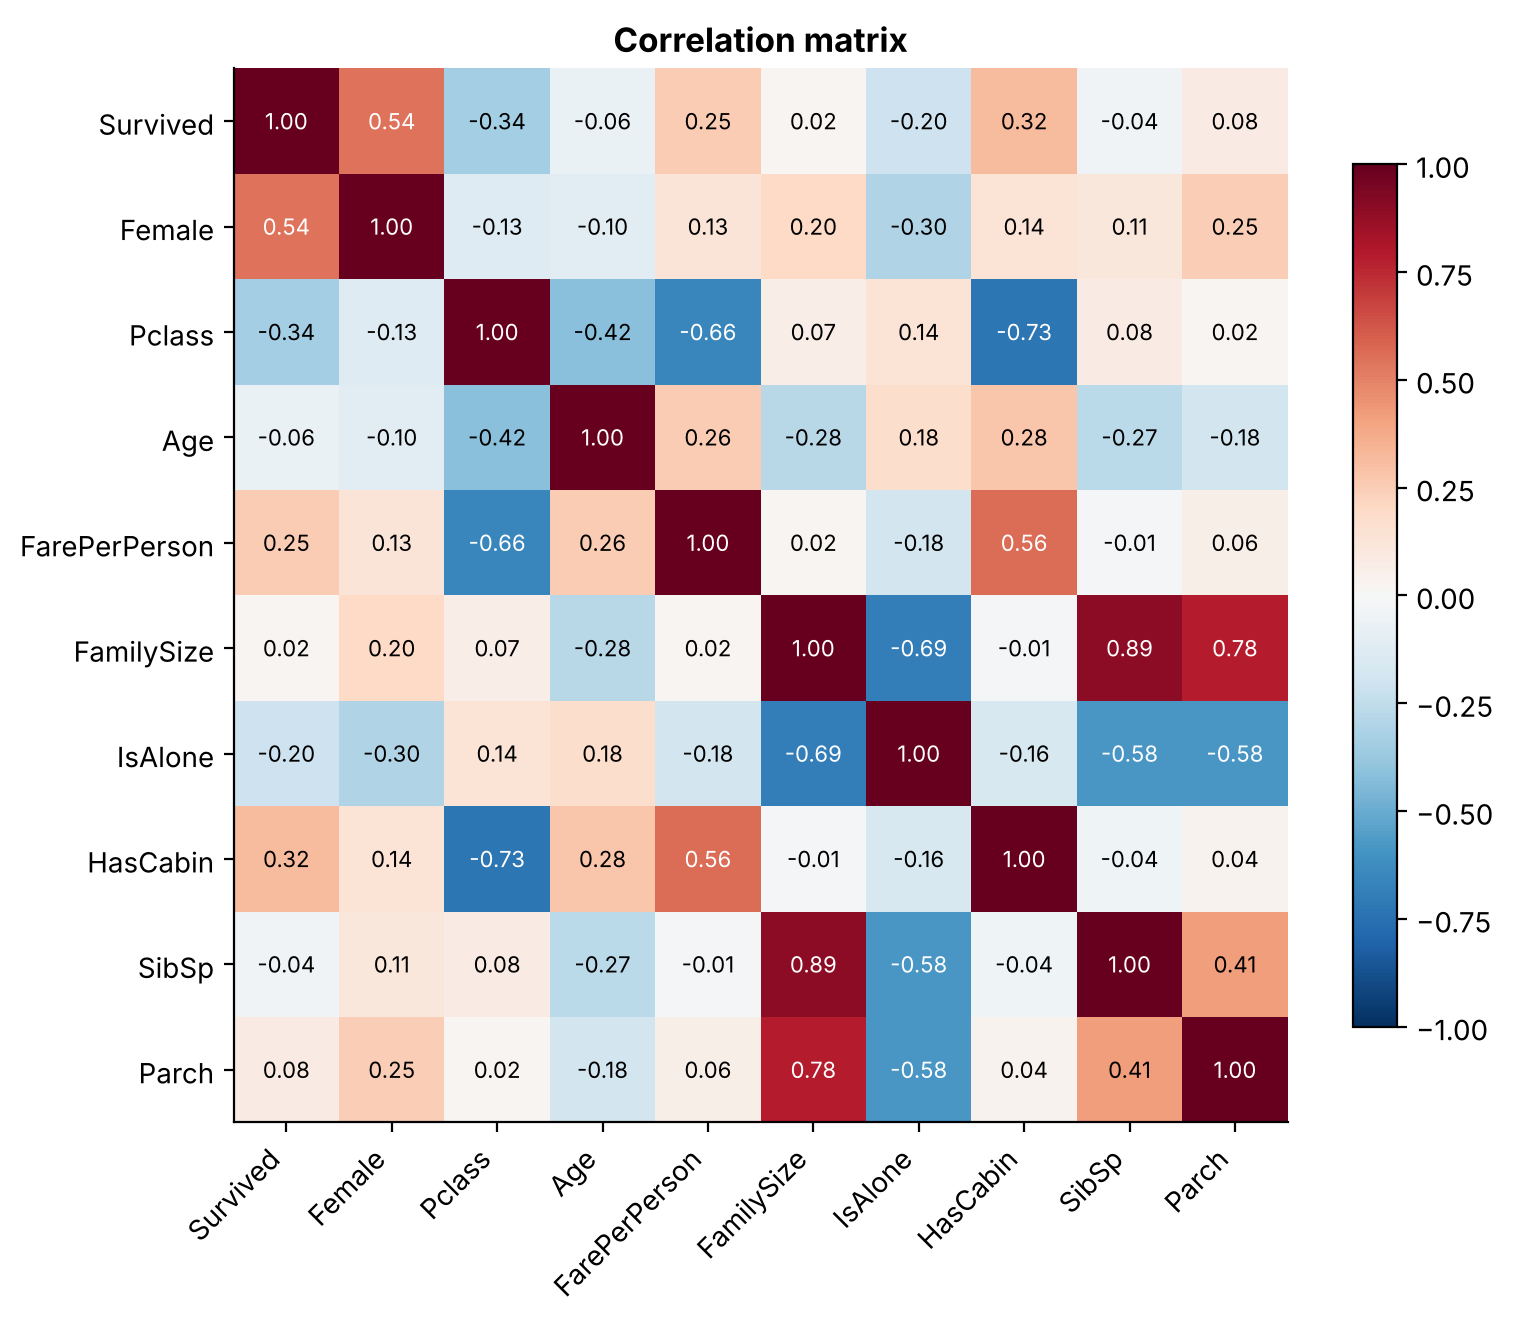

Female           0.543
Pclass          -0.338
HasCabin         0.317
FarePerPerson    0.255
IsAlone         -0.203
Parch            0.082
Age             -0.063
SibSp           -0.035
FamilySize       0.017
Name: Survived, dtype: float64

In [20]:
num = df.assign(Female=(df["Sex"] == "female").astype(int))[
    ["Survived", "Female", "Pclass", "Age", "FarePerPerson", "FamilySize", "IsAlone", "HasCabin", "SibSp", "Parch"]
]
corr = num.corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
save(fig, "09_correlation_matrix")
plt.show()

corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3)

- The strongest single predictor is sex (`Female` r = 0.54), then class (`Pclass` r = -0.34), then cabin known and fare.
- `Pclass`, `FarePerPerson` and `HasCabin` are strongly correlated with each other. They mostly carry the same information (wealth/class), which matters for model choice (multicollinearity).
- `Age` has almost no **linear** correlation with survival, even though young children clearly did better. Correlation misses non-linear patterns, which is why the grouped charts above are needed.

## 8. Hypotheses: results

In [21]:
results = pd.DataFrame([
    ["H1 Women survived more", "Supported", f"{df[df.Sex=='female'].Survived.mean():.0%} vs {df[df.Sex=='male'].Survived.mean():.0%}"],
    ["H2 Higher class survived more", "Supported",
     " / ".join(f"{v:.0%}" for v in df.groupby('Pclass').Survived.mean()) + " (1st/2nd/3rd)"],
    ["H3 Children survived more", "Partly", f"under 13: {df[df.Age<13].Survived.mean():.0%}; little age effect after that"],
    ["H4 Port mattered", "Mostly confounded by class", "Cherbourg high because of more 1st-class passengers"],
    ["H5 Family size mattered", "Supported (non-linear)", "small families 2-4 best, alone and 5+ worst"],
], columns=["Hypothesis", "Result", "Evidence"])
results

,Hypothesis,Result,Evidence
0,H1 Women survived more,Supported,74% vs 19%
1,H2 Higher class survived more,Supported,63% / 47% / 24% (1st/2nd/3rd)
2,H3 Children survived more,Partly,under 13: 58%; little age effect after that
3,H4 Port mattered,Mostly confounded by class,Cherbourg high because of more 1st-class passe...
4,H5 Family size mattered,Supported (non-linear),"small families 2-4 best, alone and 5+ worst"


## 9. Conclusions

1. Survival was 38% overall and was driven mainly by **sex**, then **class**. "Women and children first" is visible in the data, but it was applied far better in 1st and 2nd class than in 3rd.
2. A 3rd-class woman (50%) still had a better chance than a 1st-class man (37%).
3. Age only helps clearly for young children. Title captures this better than raw age.
4. Port of embarkation looks important but is mostly a class effect (a confounder).
5. Family size has an inverted-U relationship: small families did best, people alone and large families did worst.
6. Fare, cabin and class overlap heavily, so a model should not treat them as independent evidence.

## 10. Limitations and next steps

- This is the Kaggle training set only (891 of 2,224 people on board; crew not included), so the rates are estimates for passengers, not everyone on board.
- 20% of ages are imputed, so age-based results carry extra uncertainty. I kept an `AgeMissing` flag so a model can account for it.
- Some groups are small (e.g. family size 5-11, some decks), so their survival rates are noisy.
- Next step (Task 03 style): train a classifier using `Sex`, `Pclass`, `Title`, `FamilyGroup`, `AgeGroup` and `FarePerPerson`, and compare it with the simple "all women survive" baseline (about 79% accuracy on this set).

In [22]:
# Save the cleaned dataset for modelling
cols = ["PassengerId", "Survived", "Pclass", "Sex", "Age", "AgeMissing", "AgeGroup", "Title",
        "SibSp", "Parch", "FamilySize", "FamilyGroup", "IsAlone", "Fare", "FarePerPerson",
        "TicketCount", "HasCabin", "Deck", "Embarked"]
df[cols].to_csv("titanic_clean.csv", index=False)
print(df[cols].shape)
baseline = ((df["Sex"] == "female").astype(int) == df["Survived"]).mean()
print(f"Baseline accuracy (predict all women survive, all men die): {baseline:.1%}")

(891, 19)
Baseline accuracy (predict all women survive, all men die): 78.7%
